# 05. Проверка гипотез

Пять гипотез, у каждой свой метод. Структура раздела: формулировка → метод и причина выбора →
результат → вывод простыми словами. В конце: поправка Холма на множественные сравнения и отдельный разбор IT.

Обозначения: **H0** означает нулевую гипотезу («разницы нет»), **альтернатива** означает то, что проверяется.

| # | Гипотеза | Метод |
|---|---|---|
| H1 | Вакансии со скрытой зарплатой требуют больше опыта | Манн–Уитни, хи-квадрат, внутри источника |
| H2 | «Женские» вакансии платят меньше **внутри одной профессии** | стратифицированный перестановочный тест |
| H3 | Работодатели округляют зарплаты до «круглых» чисел | хи-квадрат согласия |
| H4 | Требование высшего образования **не** влияет на зарплату | тест эквивалентности (TOST) |
| H5 | Зарплаты распределены логнормально | асимметрия, Q-Q график, тест Колмогорова–Смирнова |

Уровень значимости α = 0,05.

In [1]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import matplotlib.ticker as mt
import seaborn as sns
from scipy import stats

sns.set_theme(style="whitegrid")
FIG = "../reports/figures/"
K = mt.FuncFormatter(lambda x, _: f"{x/1000:.0f}k")
rng = np.random.default_rng(42)

df = pd.read_csv("../data/processed/vacancies_clean.csv")
sal = df[df["has_salary"]].copy()
sal["log_s"] = np.log(sal["salary_kgs"])
results = []          # p-value всех тестов для поправки Холма
print(len(df), len(sal))

12646 5840


## H1. Вакансии со скрытой зарплатой требуют больше опыта

- **H0:** вакансии со скрытой и с открытой зарплатой требуют одинаковый опыт.
- **Альтернатива:** вакансии со скрытой зарплатой требуют больше опыта.

**Почему важно:** если гипотеза верна, среди видимых зарплат опытные вакансии представлены хуже,
и оценка скрытых зарплат моделью решает реальную проблему.

**Метод:** опыт задан порядковыми группами (0/1/3/6 лет), поэтому подходит тест Манна–Уитни:
он не требует нормального распределения. Сравнение идёт **отдельно по каждому источнику**:
на lalafo зарплату скрывают чаще и опыт там ниже, и общее сравнение смешало бы два эффекта.

In [2]:
rows = []
for src, g in df.groupby("source"):
    a = g.loc[g["salary_hidden"], "experience_start"]
    b = g.loc[~g["salary_hidden"], "experience_start"]
    u, p = stats.mannwhitneyu(a, b, alternative="greater")
    rows.append({"источник": src, "n_скрыта": len(a), "n_открыта": len(b),
                 "опыт_ср_скрыта": a.mean(), "опыт_ср_открыта": b.mean(),
                 "доля 3+ лет (скрыта)": (a >= 3).mean(), "доля 3+ лет (открыта)": (b >= 3).mean(),
                 "P(скрытая > открытой)": u / (len(a) * len(b)), "p_value": p})
    results.append({"тест": f"H1 опыт, {src}", "p_value": p})
h1 = pd.DataFrame(rows)
h1.round(3)

,источник,n_скрыта,n_открыта,опыт_ср_скрыта,опыт_ср_открыта,доля 3+ лет (скрыта),доля 3+ лет (открыта),P(скрытая > открытой),p_value
0,headhunter,1405,2032,1.492,1.139,0.276,0.172,0.582,0.0
1,lalafo,5111,4098,1.172,0.898,0.193,0.134,0.548,0.0


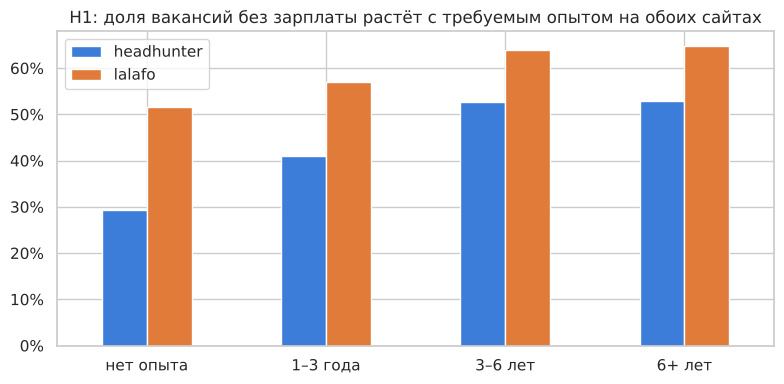

In [3]:
tab = (df.assign(скрыта=df["salary_hidden"].map({True: "скрыта", False: "открыта"}))
         .groupby(["source", "experience"])["salary_hidden"].mean().unstack()
         [["нет опыта", "1–3 года", "3–6 лет", "6+ лет"]])
ax = tab.T.plot(kind="bar", figsize=(8, 4), color=["#3b7dd8", "#e07b39"])
ax.yaxis.set_major_formatter(mt.PercentFormatter(1)); ax.set_xlabel(""); ax.legend(title="")
ax.set_title("H1: доля вакансий без зарплаты растёт с требуемым опытом на обоих сайтах")
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(FIG + "05_h1.png", dpi=150); plt.show()

**Вывод H1 простыми словами:** чем больше опыта требует вакансия, тем чаще работодатель прячет зарплату.

- На hh зарплату скрывают в 29% вакансий без опыта и в 53% вакансий с опытом от 3 лет.
- На lalafo: 52% без опыта, 65% при опыте от 6 лет.
- Среди вакансий со скрытой зарплатой опыт от 3 лет требуют 28% на hh (среди открытых только 17%)
  и 19% на lalafo (среди открытых 13%).

Разница не случайна (p < 0,001 на обоих сайтах), но умеренная: если взять наугад одну вакансию
со скрытой зарплатой и одну с открытой, первая требует больше опыта в 58% случаев на hh и в 55% на lalafo
(50% означало бы отсутствие разницы).

**Что это значит:** среди видимых зарплат больше вакансий для начинающих, поэтому медиана рынка
(39 000 сом), скорее всего, ближе к их уровню оплаты. Сколько на самом деле платят по скрытым вакансиям,
эти данные не показывают: эту задачу решает ML-модель.

## H2. «Женские» вакансии платят меньше даже внутри одной профессии

- **H0:** внутри одной профессии требование «девушка/женщина» не связано с зарплатой.
- **Альтернатива:** такие вакансии платят меньше.

**Почему не простой тест:** «женские» объявления чаще встречаются в низкооплачиваемых профессиях
(продавец, швея, уборщица). Простое сравнение покажет разницу профессий, а не пола.

**Метод: стратифицированный перестановочный тест.**
1. Данные: только lalafo (на hh требований к полу нет) и профессии (sub_category),
   где есть не меньше 5 «женских» и 5 обычных вакансий.
2. Статистика: средняя разница log(зарплаты) внутри профессии, взвешенная по числу «женских» вакансий.
3. Метка «для женщин» 10 000 раз случайно перемешивается **только внутри каждой профессии**,
   и каждый раз статистика считается заново.
4. p-value: доля перестановок, где разница по модулю не меньше реальной.

Тест не требует никаких предположений о распределении зарплат.

In [4]:
lal = sal[(sal["source"] == "lalafo") & sal["gender_req"].isin(["женщины", "не указано"])].copy()
lal["female"] = lal["gender_req"] == "женщины"
cnt = lal.groupby("sub_category")["female"].agg(f="sum", n="size")
cnt["o"] = cnt["n"] - cnt["f"]
strata = cnt[(cnt["f"] >= 5) & (cnt["o"] >= 5)].index
st = lal[lal["sub_category"].isin(strata)].copy()
print(f"Профессий: {len(strata)} | вакансий: {len(st)} | из них «для женщин»: {st['female'].sum()}")

groups = [(g["log_s"].to_numpy(), g["female"].to_numpy()) for _, g in st.groupby("sub_category")]

def stat(gs):
    num = den = 0.0
    for y, f in gs:
        w = f.sum()
        num += w * (y[f].mean() - y[~f].mean()); den += w
    return num / den

obs = stat(groups)
perm = np.empty(10_000)
for i in range(len(perm)):
    perm[i] = stat([(y, rng.permutation(f)) for y, f in groups])
p_h2 = (np.abs(perm) >= abs(obs)).mean()
p_h2 = max(p_h2, 1 / len(perm))
results.append({"тест": "H2 пол внутри профессии", "p_value": p_h2})
print(f"Разница внутри профессии: {np.expm1(obs):+.1%}  |  p = {p_h2:.4f}")

Профессий: 15 | вакансий: 2140 | из них «для женщин»: 348


Разница внутри профессии: -5.6%  |  p = 0.0444


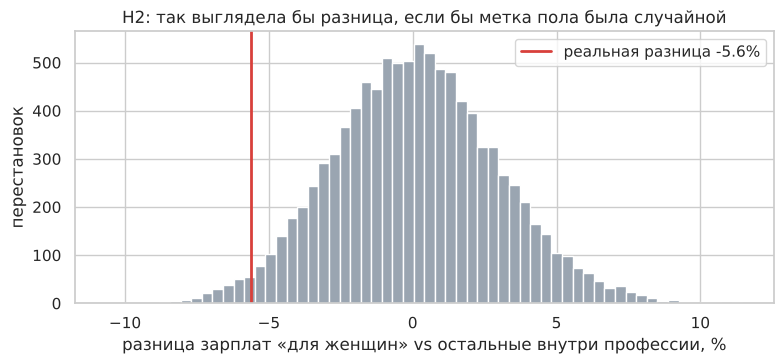

In [5]:
fig, ax = plt.subplots(figsize=(8, 3.8))
ax.hist(np.expm1(perm) * 100, bins=60, color="#9aa5b1")
ax.axvline(np.expm1(obs) * 100, color="#d8403b", lw=2, label=f"реальная разница {np.expm1(obs):+.1%}")
ax.set_xlabel("разница зарплат «для женщин» vs остальные внутри профессии, %")
ax.set_ylabel("перестановок"); ax.legend()
ax.set_title("H2: так выглядела бы разница, если бы метка пола была случайной")
plt.tight_layout(); plt.savefig(FIG + "05_h2.png", dpi=150); plt.show()

In [6]:
# по профессиям
by = st.groupby(["sub_category", "female"])["salary_kgs"].median().unstack()
by["разница_%"] = (by[True] / by[False] - 1) * 100
by.join(cnt[["f", "o"]]).sort_values("разница_%").round(0)

,False,True,разница_%,f,o
sub_category,,,,,
Специалист по подбору персонала,45000.0,25000.0,-44.0,5,8
"Повар, пекарь, кондитер",39000.0,28600.0,-27.0,27,254
"Менеджер по продажам, менеджер по работе с клиентами",40000.0,30000.0,-25.0,15,73
Другое,30000.0,25000.0,-17.0,20,247
Хостес,33800.0,28600.0,-15.0,5,10
Другие специальности,35000.0,30000.0,-14.0,35,334
"Продавец-консультант, продавец-кассир",30000.0,26000.0,-13.0,92,124
"Швея, портной, закройщик",43300.0,40000.0,-8.0,22,224
"Официант, бармен, бариста",32500.0,30600.0,-6.0,26,106


**Вывод H2 простыми словами:** если сравнивать все объявления сразу, вакансии «для женщин» на lalafo
платят на 18% меньше (ноутбук 04). Но если сравнивать одну и ту же профессию (продавца с продавцом,
повара с поваром), разница сокращается до **6%**.

Такой разрыв на грани случайности: p = 0,044, и после поправки Холма результат незначим.
По отдельным профессиям картина разная: у поваров «женские» вакансии платят на 27% меньше,
у продавцов на 13% меньше, а у администраторов и кассиров, наоборот, больше.

**Что это значит:** основная причина разрыва в другом. Слово «девушка» чаще пишут в объявлениях
о **низкооплачиваемых профессиях** (продавец, швея, уборщица). Такое явление называется
профессиональной сегрегацией. Это связь, а не доказательство дискриминации.
Ограничение: всего 15 профессий и 348 «женских» вакансий.

## H3. Работодатели округляют зарплаты

- **H0:** среди зарплат, кратных 1 000, цифра тысяч распределена равномерно (каждая из 0–9 встречается в 10% случаев).
- **Альтернатива:** «круглые» десятки тысяч (цифра 0) встречаются чаще.

**Метод:** хи-квадрат согласия по цифре тысяч. В расчёт входят только месячные зарплаты в сомах:
после пересчёта дневных ставок и валют округление пропадает искусственно.

**Зачем:** округление объясняет «ступенчатость» распределения и ошибки модели: реальные зарплаты
собраны вокруг 30, 40, 50 тыс., а модель предсказывает непрерывное число.

Месячных зарплат: 4375 | кратны 1 000: 90% | кратны 10 000: 53%
Среди кратных 1 000 цифра тысяч = 0: 59% (ожидалось 10%)
chi2 = 13279, p = 0.0e+00


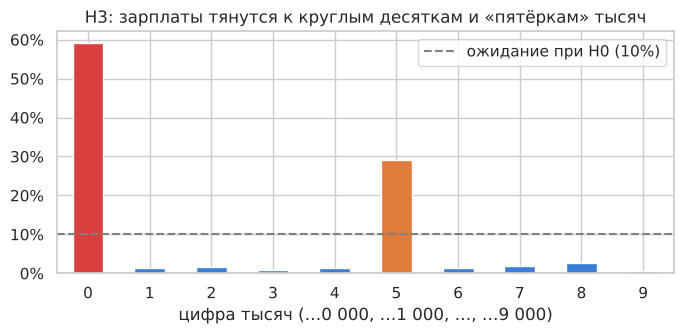

In [7]:
m = sal[(sal["pay_period"] == "month") & (sal["compensation_currency"] == "KGS")]["salary_kgs"].round()
k = m[m % 1000 == 0]
digit = ((k // 1000) % 10).astype(int)
obs_d = digit.value_counts().reindex(range(10), fill_value=0)
chi2, p_h3 = stats.chisquare(obs_d)
results.append({"тест": "H3 округление", "p_value": p_h3})
print(f"Месячных зарплат: {len(m)} | кратны 1 000: {(m % 1000 == 0).mean():.0%} | "
      f"кратны 10 000: {(m % 10000 == 0).mean():.0%}")
print(f"Среди кратных 1 000 цифра тысяч = 0: {obs_d[0] / obs_d.sum():.0%} (ожидалось 10%)")
print(f"chi2 = {chi2:.0f}, p = {p_h3:.1e}")

ax = (obs_d / obs_d.sum()).plot(kind="bar", figsize=(7, 3.5), color=["#d8403b"] + ["#3b7dd8"] * 4 + ["#e07b39"] + ["#3b7dd8"] * 4)
ax.axhline(0.1, color="grey", ls="--", label="ожидание при H0 (10%)")
ax.yaxis.set_major_formatter(mt.PercentFormatter(1))
ax.legend(handles=[ax.lines[0]], labels=["ожидание при H0 (10%)"])
ax.set_xlabel("цифра тысяч (…0 000, …1 000, …, …9 000)")
ax.set_title("H3: зарплаты тянутся к круглым десяткам и «пятёркам» тысяч")
plt.xticks(rotation=0); plt.tight_layout(); plt.savefig(FIG + "05_h3.png", dpi=150); plt.show()

**Вывод H3 простыми словами:** работодатели почти всегда пишут круглые суммы.

- 90% месячных зарплат кратны 1 000 сом, 53% кратны 10 000.
- Среди сумм, кратных 1 000, ровные десятки тысяч (30 000, 40 000…) составляют **59%**,
  хотя при отсутствии округления было бы 10%. Ещё 29% заканчиваются на 5 000 (35 000, 45 000…).
- Вместе это 88%: почти все зарплаты выбираются из короткого списка «удобных» чисел.

Отклонение от равномерности огромное (хи-квадрат = 13 279, p ≈ 0).

**Что это значит для модели:** ошибка в 3–5 тыс. сом во многом неизбежна, потому что реальные
зарплаты «прыгают» шагами по 5–10 тыс.

## H4. Требование высшего образования не влияет на зарплату (тест эквивалентности)

Обычный тест умеет сказать только «разница не найдена», и это **не** доказательство её отсутствия.
**TOST** (two one-sided tests) проверяет, что разница лежит внутри заранее выбранной «зоны безразличия».

- Зона: ±5% к зарплате (меньшую разницу соискатель практически не заметит).
- **H0:** разница по модулю не меньше 5%. **Альтернатива:** разница меньше 5%, то есть группы эквивалентны.
- Влияние сферы убрано через **остатки**: log(зарплаты) минус среднее по
  своей группе «категория × источник».
- Тот же тест проведён для удалённой работы.

In [8]:
sal["resid"] = sal["log_s"] - sal.groupby(["category", "source"])["log_s"].transform("mean")
MARGIN = np.log(1.05)

def tost(a, b, margin=MARGIN):
    a, b = np.asarray(a), np.asarray(b)
    d = a.mean() - b.mean()
    va, vb = a.var(ddof=1) / len(a), b.var(ddof=1) / len(b)
    se = np.sqrt(va + vb)
    df_ = (va + vb) ** 2 / (va ** 2 / (len(a) - 1) + vb ** 2 / (len(b) - 1))   # Уэлч
    p_low = 1 - stats.t.cdf((d + margin) / se, df_)
    p_high = stats.t.cdf((d - margin) / se, df_)
    ci = d + np.array([-1, 1]) * stats.t.ppf(0.95, df_) * se                    # 90% ДИ для TOST
    return {"n_A": len(a), "n_B": len(b), "разница_%": np.expm1(d) * 100,
            "90% ДИ от_%": np.expm1(ci[0]) * 100, "90% ДИ до_%": np.expm1(ci[1]) * 100,
            "p_TOST": max(p_low, p_high)}

h4 = pd.DataFrame([
    {"сравнение": "высшее образование vs не указано",
     **tost(sal.loc[sal.education == "высшее", "resid"], sal.loc[sal.education == "не указано", "resid"])},
    {"сравнение": "удалёнка vs нет",
     **tost(sal.loc[sal.remote, "resid"], sal.loc[~sal.remote, "resid"])},
])
h4["эквивалентны (±5%)"] = np.where(h4["p_TOST"] < 0.05, "да", "не доказано")
for _, r in h4.iterrows():
    results.append({"тест": f"H4 TOST {r['сравнение']}", "p_value": r["p_TOST"]})
h4.round(3)

,сравнение,n_A,n_B,разница_%,90% ДИ от_%,90% ДИ до_%,p_TOST,эквивалентны (±5%)
0,высшее образование vs не указано,453,5359,1.113,-2.530,4.891,0.045,да
1,удалёнка vs нет,82,5758,-3.948,-12.273,5.166,0.438,не доказано


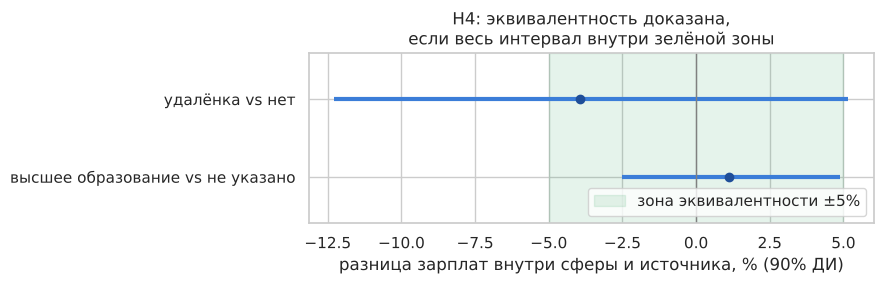

In [9]:
fig, ax = plt.subplots(figsize=(9, 3))
for i, r in h4.iterrows():
    ax.hlines(i, r["90% ДИ от_%"], r["90% ДИ до_%"], color="#3b7dd8", lw=3)
    ax.scatter(r["разница_%"], i, color="#1f4e99", zorder=3)
ax.axvspan(-5, 5, color="#2e9e5b", alpha=.12, label="зона эквивалентности ±5%")
ax.axvline(0, color="grey", lw=1)
ax.set_yticks(range(len(h4))); ax.set_yticklabels(h4["сравнение"]); ax.set_ylim(-0.6, len(h4) - 0.4)
ax.set_xlabel("разница зарплат внутри сферы и источника, % (90% ДИ)"); ax.legend(loc="lower right")
ax.set_title("H4: эквивалентность доказана,\nесли весь интервал внутри зелёной зоны")
plt.tight_layout(); plt.savefig(FIG + "05_h4.png", dpi=150); plt.show()

**Как читать:** если весь интервал внутри зелёной зоны, разница меньше 5% доказана.
Если интервал выходит за зону, данных недостаточно для вывода об эквивалентности
(и это не означает, что разница есть).

**Вывод H4 простыми словами:** в одной и той же сфере вакансии, где требуют высшее образование,
платят почти столько же, сколько остальные: **разница около +1%**. Даже в худшем случае
она укладывается в интервал от −2,5% до +4,9%, то есть меньше 5%.

Значит, требование диплома практически не влияет на предлагаемую зарплату.
Оговорка: результат на грани (p = 0,045) и после строгой поправки Холма незначим.

Про удалённую работу вывод сделать нельзя: таких вакансий всего 82, и разница может быть
от −12% до +5%.

## H5. Зарплаты распределены логнормально

- **H0:** log(зарплаты) распределён нормально.

**Зачем:** если гипотеза верна, модель стоит обучать на log(зарплаты): ошибки становятся симметричными,
а редкие высокие зарплаты не перетягивают модель на себя. Это прямая связь анализа с ML-проектом.

**Важная оговорка:** при 5 800 наблюдениях тест Колмогорова–Смирнова отвергает нормальность
из-за **любого** малого отклонения, а округление из H3 уже является таким отклонением. Поэтому
дополнительно используются асимметрия и Q-Q график: вопрос не в том, идеально ли распределение
нормальное, а в том, достаточно ли оно близко для модели.

Асимметрия: исходные 4.25 → после логарифма 0.48
KS: D = 0.080, p = 8.1e-33


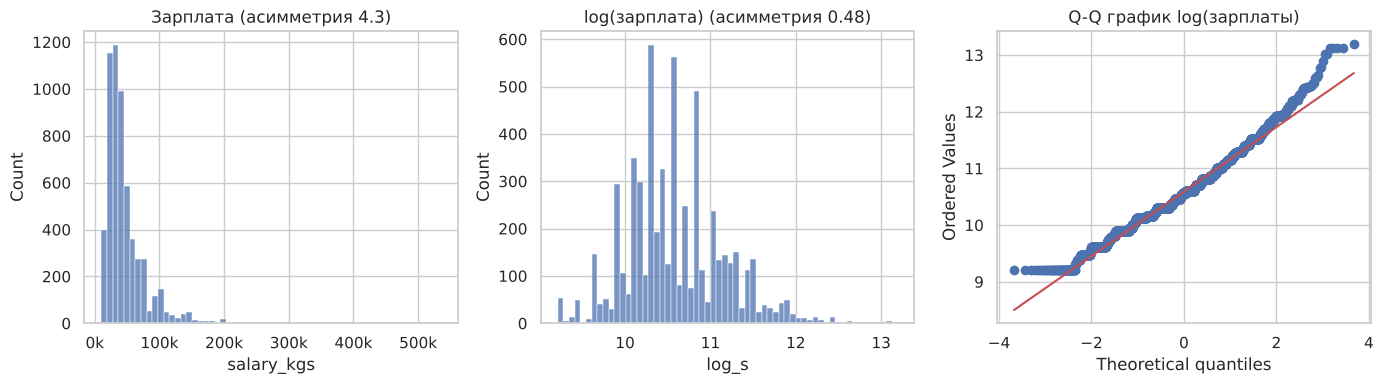

In [10]:
x, lx = sal["salary_kgs"], sal["log_s"]
ks = stats.kstest((lx - lx.mean()) / lx.std(), "norm")
results.append({"тест": "H5 KS log-нормальность", "p_value": ks.pvalue})
print(f"Асимметрия: исходные {stats.skew(x):.2f} → после логарифма {stats.skew(lx):.2f}")
print(f"KS: D = {ks.statistic:.3f}, p = {ks.pvalue:.1e}")

fig, ax = plt.subplots(1, 3, figsize=(14, 4))
sns.histplot(x, bins=60, ax=ax[0]); ax[0].xaxis.set_major_formatter(K); ax[0].set_title(f"Зарплата (асимметрия {stats.skew(x):.1f})")
sns.histplot(lx, bins=60, ax=ax[1]); ax[1].set_title(f"log(зарплата) (асимметрия {stats.skew(lx):.2f})")
stats.probplot(lx, dist="norm", plot=ax[2]); ax[2].set_title("Q-Q график log(зарплаты)")
plt.tight_layout(); plt.savefig(FIG + "05_h5.png", dpi=150); plt.show()

**Вывод H5 простыми словами:** обычные зарплаты сильно «перекошены»: большинство в районе
25–55 тыс., но есть длинный хвост до 500 тыс. (асимметрия **4,3**). После логарифма распределение
становится почти симметричным (асимметрия **0,5**), а Q-Q график близок к прямой.

Строгий тест всё же отвергает идеальную нормальность (D = 0,08, p ≈ 0), но отклонение небольшое
и объясняется большим объёмом данных и округлением из H3.

**Решение для ML:** модель предсказывает log(зарплаты), а результат переводится обратно в сомы.

## Поправка на множественные сравнения (метод Холма)

В ноутбуке проведено 7 тестов. При α = 0,05 и 7 тестах шанс получить хотя бы один ложный
«значимый» результат около 30%. Метод Холма ужесточает порог последовательно:
самое маленькое p сравнивается с α/7, следующее с α/6 и так далее до первого провала.

In [11]:
res = pd.DataFrame(results).sort_values("p_value").reset_index(drop=True)
m_ = len(res)
res["порог Холма"] = [0.05 / (m_ - i) for i in range(m_)]
passed = (res["p_value"] <= res["порог Холма"]).cummin()   # после первого провала все следующие незначимы
res["значимо после Холма"] = np.where(passed, "да", "нет")
res

,тест,p_value,порог Холма,значимо после Холма
0,H3 округление,0.000000e+00,0.007143,да
1,H5 KS log-нормальность,8.130427e-33,0.008333,да
2,"H1 опыт, headhunter",2.329038e-20,0.010000,да
3,"H1 опыт, lalafo",3.366659e-18,0.012500,да
4,H2 пол внутри профессии,4.440000e-02,0.016667,нет
5,H4 TOST высшее образование vs не указано,4.540793e-02,0.025000,нет
6,H4 TOST удалёнка vs нет,4.381815e-01,0.050000,нет


**Итог поправки:** устойчивыми остаются 4 из 7 тестов: H1 (на обоих сайтах), H3 и формальный тест H5.
Результаты H2 и H4 (p ≈ 0,045) проходят обычный порог 0,05, но не строгий, поэтому их правильно
называть «пограничными».

## Отдельно: IT-вакансии

Данных по IT мало для отдельной модели, но достаточно для описательного разбора.
Определение IT шире категории: категория «Информационные технологии» **или** IT-слово в названии вакансии.

In [12]:
it_kw = (r"программист|разработчик|developer|frontend|backend|fullstack|python|java|devops|"
         r"тестировщик|qa |аналитик данных|data|системн.{0,4} администратор|web|веб|1с-|1с |ux|ui")
is_it = (df["category"] == "Информационные технологии") | df["name"].str.lower().str.contains(it_kw)
it = df[is_it]
it_s = it[it["has_salary"]]
print(f"IT-вакансий: {len(it)} | с зарплатой: {len(it_s)} | скрыли: {it['salary_hidden'].mean():.0%} "
      f"(рынок: {df['salary_hidden'].mean():.0%})")
print(it_s.groupby("source")["salary_kgs"].agg(["median", "size"]))

IT-вакансий: 255 | с зарплатой: 102 | скрыли: 60% (рынок: 52%)
             median  size
source                   
headhunter  80000.0    61
lalafo      30000.0    41


In [13]:
a = it_s.loc[it_s.source == "headhunter", "salary_kgs"]; b = it_s.loc[it_s.source == "lalafo", "salary_kgs"]
u, p = stats.mannwhitneyu(a, b)
print(f"IT: hh vs lalafo, медианы {a.median():,.0f} vs {b.median():,.0f}, p = {p:.1e}, P(hh>lalafo) = {u/(len(a)*len(b)):.2f}")
print("\nIT по опыту:")
print(it_s.groupby("experience")["salary_kgs"].agg(["median", "size"]).reindex(["нет опыта", "1–3 года", "3–6 лет", "6+ лет"]))
print("\nЧастые IT-вакансии на lalafo (что там на самом деле):")
print(it[it.source == "lalafo"]["name"].str.slice(0, 60).value_counts().head(8))

IT: hh vs lalafo, медианы 80,000 vs 30,000, p = 4.2e-10, P(hh>lalafo) = 0.87

IT по опыту:
              median  size
experience                
нет опыта    30000.0    27
1–3 года     50000.0    51
3–6 лет      97500.0    22
6+ лет      166333.1     2

Частые IT-вакансии на lalafo (что там на самом деле):
name
IT, компьютеры, связь                                           3
Привет, тебе нужна работа с гибким графиком Тогда ты читаешь    2
Требуется только девушка на компьютерные услуги (Оператор ПК    1
В организацию требуются монтажники, связисты. Требования: Оп    1
Требуется в типографию оператор ПК (персонального компьютера    1
Требуется специалист по чат ботам в Телеграм, VK. Для одного    1
На работу в сервисный центр требуются сотрудники. От Вас: Оп    1
На работу в сервисный центр требуется мастера по ремонту ком    1
Name: count, dtype: int64


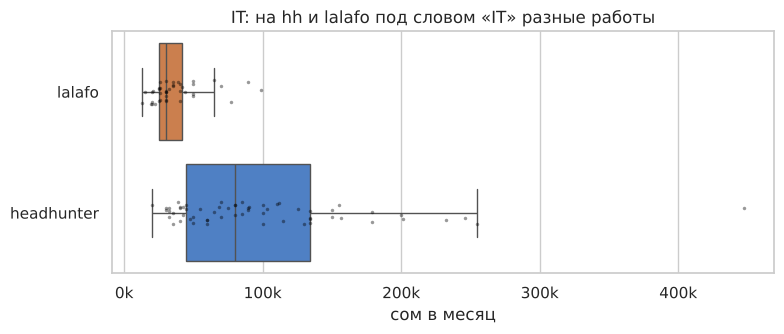

In [14]:
fig, ax = plt.subplots(figsize=(8, 3.5))
sns.boxplot(data=it_s, x="salary_kgs", y="source", hue="source", palette={"headhunter": "#3b7dd8", "lalafo": "#e07b39"},
            showfliers=False, ax=ax, legend=False)
sns.stripplot(data=it_s, x="salary_kgs", y="source", color="black", size=2.5, alpha=.4, ax=ax)
ax.xaxis.set_major_formatter(K); ax.set_xlabel("сом в месяц"); ax.set_ylabel("")
ax.set_title("IT: на hh и lalafo под словом «IT» разные работы")
plt.tight_layout(); plt.savefig(FIG + "05_it.png", dpi=150); plt.show()

**Вывод по IT простыми словами:** под словом «IT» на двух сайтах понимают разную работу.

- На hh это разработка и администрирование: медиана **80 000** сом.
- На lalafo это операторы ПК, ремонт техники, «работа с гибким графиком»: медиана **30 000** сом.
- Разница огромная: вакансия с hh платит больше в 87% случайных пар.
- Опыт в IT окупается сильнее, чем на рынке в целом: при опыте 3–6 лет медиана 97 500 против
  30 000 без опыта, то есть больше чем втрое (на всём рынке только +54%).
- IT скрывает зарплату чаще рынка: 60% против 52%.

Всего 102 IT-зарплаты: этого хватает для описания, но не для отдельной модели.

## Итоги проверки гипотез

| # | Гипотеза | Результат | После Холма |
|---|---|---|---|
| # | Гипотеза | Результат простыми словами | После Холма |
|---|---|---|---|
| H1 | Скрытые зарплаты чаще у вакансий с опытом | **да**: на hh скрывают 29% вакансий без опыта и 53% с опытом 3+ лет | значимо |
| H2 | «Женские» вакансии платят меньше в той же профессии | разница всего 6% (в целом 18%): разрыв в основном из-за разных профессий | незначимо |
| H3 | Работодатели округляют зарплаты | **да**: 88% «тысячных» зарплат заканчиваются на 0 000 или 5 000 | значимо |
| H4 | Диплом не влияет на зарплату | разница около +1%, точно меньше 5% | незначимо (на грани) |
| H5 | Зарплаты логнормальны | приблизительно: асимметрия падает с 4,3 до 0,5 | формально отвергнута |

**Что это даёт ML-проекту:**
- модель предсказывает **log(зарплаты)** (H5);
- ошибку модели в несколько тысяч сом стоит объяснять округлением (H3);
- самая ценная часть модели: оценка скрытых зарплат опытных специалистов (H1);
- требование образования почти не несёт информации о зарплате (H4).

**Методы:** непараметрические тесты, перестановочный тест со стратификацией,
тест эквивалентности и поправка на множественные сравнения. Для каждого результата указан
размер эффекта, а не только p-value.